# Formula 1 Podium Prediction: Milestone 1 (CSEN 903 ACL)
Predict whether each driver finishes on the podium (`positionOrder <= 3`) using only information known after qualifying and before the race.

## 1. Setup

### 1.1 Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


### 1.2 Data path
Defaults to the Kaggle input folder; set the `F1_DATA_DIR` environment variable to run locally.

In [ ]:
import os

DATA_DIR = Path(os.environ.get(
    'F1_DATA_DIR',
    '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'
))

print("Data directory:", DATA_DIR)

## 2. Load the Dataset (14 tables)

In [2]:
# Load all 14 CSV files

results = pd.read_csv(
    DATA_DIR / 'results.csv',
    na_values=[r'\N']
)

races = pd.read_csv(
    DATA_DIR / 'races.csv',
    na_values=[r'\N']
)

drivers = pd.read_csv(
    DATA_DIR / 'drivers.csv',
    na_values=[r'\N']
)

constructors = pd.read_csv(
    DATA_DIR / 'constructors.csv',
    na_values=[r'\N']
)

qualifying = pd.read_csv(
    DATA_DIR / 'qualifying.csv',
    na_values=[r'\N']
)

status = pd.read_csv(
    DATA_DIR / 'status.csv',
    na_values=[r'\N']
)

circuits = pd.read_csv(
    DATA_DIR / 'circuits.csv',
    na_values=[r'\N']
)

constructor_results = pd.read_csv(
    DATA_DIR / 'constructor_results.csv',
    na_values=[r'\N']
)

constructor_standings = pd.read_csv(
    DATA_DIR / 'constructor_standings.csv',
    na_values=[r'\N']
)

driver_standings = pd.read_csv(
    DATA_DIR / 'driver_standings.csv',
    na_values=[r'\N']
)

lap_times = pd.read_csv(
    DATA_DIR / 'lap_times.csv',
    na_values=[r'\N']
)

pit_stops = pd.read_csv(
    DATA_DIR / 'pit_stops.csv',
    na_values=[r'\N']
)

sprint_results = pd.read_csv(
    DATA_DIR / 'sprint_results.csv',
    na_values=[r'\N']
)

seasons = pd.read_csv(
    DATA_DIR / 'seasons.csv',
    na_values=[r'\N']  # treat \N as missing
)


tables = {
    'results': results,
    'races': races,
    'drivers': drivers,
    'constructors': constructors,
    'qualifying': qualifying,
    'status': status,
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'driver_standings': driver_standings,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'sprint_results': sprint_results,
    'seasons': seasons
}

# Check that all tables are loaded
print("Number of tables:", len(tables))

for name, df in tables.items():
    print(name, ":", df.shape)


Number of tables: 14
results : (26759, 18)
races : (1125, 18)
drivers : (861, 9)
constructors : (212, 5)
qualifying : (10494, 9)
status : (139, 2)
circuits : (77, 9)
constructor_results : (12625, 5)
constructor_standings : (13391, 7)
driver_standings : (34863, 7)
lap_times : (589081, 6)
pit_stops : (11371, 7)
sprint_results : (360, 16)
seasons : (75, 2)


## 3. Raw Data Audit
Read-only checks on the raw tables; the findings here motivate the cleaning steps in Section 4.

### 3.1 results.csv: overview

In [3]:
results.head() # Display the first five rows
results.info() # Check data types, non-null counts and columns
results.describe() # Statistical summary
results.isnull().sum() # Count missing values per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

### 3.2 Primary key checks

In [7]:
primary_keys = {
    'results': ['resultId'],
    'races': ['raceId'],
    'drivers': ['driverId'],
    'constructors': ['constructorId'],
    'qualifying': ['qualifyId'],
    'status': ['statusId'],
    'circuits': ['circuitId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
    'seasons': ['year']
}


In [8]:
for table_name, key_columns in primary_keys.items():

    df = tables[table_name]

    # Count rows with at least one missing key component
    missing_keys = df[key_columns].isnull().any(axis=1).sum()

    # Count repeated keys
    duplicate_keys = df.duplicated(
        subset=key_columns
    ).sum()

    print("Table:", table_name)
    print("Primary key:", key_columns)
    print("Missing key rows:", missing_keys)
    print("Duplicate keys:", duplicate_keys)
    print("-" * 45)


Table: results
Primary key: ['resultId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: races
Primary key: ['raceId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: drivers
Primary key: ['driverId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructors
Primary key: ['constructorId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: qualifying
Primary key: ['qualifyId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: status
Primary key: ['statusId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: circuits
Primary key: ['circuitId']
Missing key rows: 0
Duplicate keys: 0
---------------------------------------------
Table: constructor_results
Primary key: ['constructorResultsId']
Missing key rows: 0
Duplicate keys: 0
-----------

### 3.3 Foreign key checks

In [9]:
foreign_keys = {
    'results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ],

    'races': [
        ('year', 'seasons', 'year'),
        ('circuitId', 'circuits', 'circuitId')
    ],

    'qualifying': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_results': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'constructor_standings': [
        ('raceId', 'races', 'raceId'),
        ('constructorId', 'constructors', 'constructorId')
    ],

    'driver_standings': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'lap_times': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'pit_stops': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId')
    ],

    'sprint_results': [
        ('raceId', 'races', 'raceId'),
        ('driverId', 'drivers', 'driverId'),
        ('constructorId', 'constructors', 'constructorId'),
        ('statusId', 'status', 'statusId')
    ]
}


In [10]:
foreign_key_results = []

for table_name, relationships in foreign_keys.items():

    df = tables[table_name]

    for foreign_key, ref_table, primary_key in relationships:

        # Count missing foreign keys
        missing_count = df[foreign_key].isnull().sum()

        # Check whether IDs exist in the referenced table
        invalid = (
            ~df[foreign_key].isin(tables[ref_table][primary_key])
        ) & df[foreign_key].notna()

        invalid_count = invalid.sum()

        foreign_key_results.append({
            'Table': table_name,
            'Foreign Key': foreign_key,
            'References': ref_table,
            'Missing Values': missing_count,
            'Invalid References': invalid_count
        })

fk_audit = pd.DataFrame(foreign_key_results)

display(fk_audit)


,Table,Foreign Key,References,Missing Values,Invalid References
0,results,raceId,races,0,0
1,results,driverId,drivers,0,0
2,results,constructorId,constructors,0,0
3,results,statusId,status,0,0
4,races,year,seasons,0,0
5,races,circuitId,circuits,0,0
6,qualifying,raceId,races,0,0
7,qualifying,driverId,drivers,0,0
8,qualifying,constructorId,constructors,0,0
9,constructor_results,raceId,races,0,0


### 3.4 Missing values per table

In [11]:
for name, df in tables.items():

    print("\nTable:", name)

    missing = df.isnull().sum()

    print(
        missing[missing > 0]
        .sort_values(ascending=False)
    )

    print("-" * 45)



Table: results
milliseconds       19079
time               19079
fastestLapTime     18507
fastestLap         18507
fastestLapSpeed    18507
rank               18249
position           10953
number                 6
dtype: int64
---------------------------------------------

Table: races
sprint_time    1110
sprint_date    1107
fp3_time       1072
quali_time     1057
fp2_time       1057
fp1_time       1057
fp3_date       1053
fp2_date       1035
fp1_date       1035
quali_date     1035
time            731
dtype: int64
---------------------------------------------

Table: drivers
number    802
code      757
dtype: int64
---------------------------------------------

Table: constructors
Series([], dtype: int64)
---------------------------------------------

Table: qualifying
q3    6865
q2    4647
q1     156
dtype: int64
---------------------------------------------

Table: status
Series([], dtype: int64)
---------------------------------------------

Table: circuits
Series([], dtype: int64

### 3.5 Duplicate (raceId, driverId) rows in results

In [4]:
# Check completely identical rows
print("Exact duplicates:", results.duplicated().sum())

# Check drivers appearing more than once in the same race
print(
    "Duplicate driver-race combinations:",
    results.duplicated(
        subset=['raceId', 'driverId']
    ).sum()
)

Exact duplicates: 0
Duplicate driver-race combinations: 91


In [5]:
duplicates = results[
    results.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].copy()

# Display the important columns
display(
    duplicates[
        ['resultId', 'raceId', 'driverId',
         'constructorId', 'grid', 'positionOrder',
         'points', 'statusId']
    ].sort_values(['raceId', 'driverId'])
)


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,statusId
13188,13189,540,229,54,0,26,0.0,81
13191,13192,540,229,57,0,29,0.0,97
17362,17363,717,373,172,1,7,0.0,60
24298,24304,717,373,172,1,12,0.0,98
17740,17741,733,465,172,0,22,0.0,54
...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,15,6,0.0,18
20163,20164,839,579,51,1,15,1.0,6
20183,20184,839,579,51,7,13,0.0,5
20165,20166,839,647,6,2,17,0.0,5


In [6]:
# Add the race year
duplicates_details = pd.merge(
    duplicates,
    races[['raceId', 'year', 'name']],
    on='raceId',
    how='left'
)

# Add driver names
duplicates_details = pd.merge(
    duplicates_details,
    drivers[['driverId', 'forename', 'surname']],
    on='driverId',
    how='left'
)

# Add constructor names to duplicated records
duplicates_details = pd.merge(
    duplicates_details,
    constructors[['constructorId', 'name']],
    on='constructorId',
    how='left',
    suffixes=('', '_constructor')
)

# Display the results
display(
    duplicates_details[
        ['year', 'name', 'forename', 'surname',
         'raceId', 'driverId', 'constructorId', 'name_constructor', 'resultId',
         'grid', 'positionOrder', 'points']
    ].sort_values(['year', 'raceId', 'driverId'])
    .head(30)
)

# Count duplicate groups with multiple constructors
constructor_counts = (
    duplicates.groupby(['raceId', 'driverId'])
    ['constructorId'].nunique()
)

print(
    "Groups with different constructors:",
    (constructor_counts > 1).sum()
)

print(
    "Groups with the same constructor:",
    (constructor_counts == 1).sum()
)

# Check for multiple non-zero grid positions
grid_counts = (
    duplicates[duplicates['grid'] > 0]
    .groupby(['raceId', 'driverId'])
    .size()
)

print(
    "Groups with multiple positive grid positions:",
    (grid_counts > 1).sum()
)

# Check duplicate groups with conflicting podium outcomes
podium_counts = (
    duplicates.assign(
        podium=(duplicates['positionOrder'] <= 3).astype(int)
    )
    .groupby(['raceId', 'driverId'])
    ['podium'].nunique()
)

print(
    "Groups with conflicting podium labels:",
    (podium_counts > 1).sum()
)



,year,name,forename,surname,raceId,driverId,constructorId,name_constructor,resultId,grid,positionOrder,points
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,150,Deidt,20097,8,31,0.0
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,113,Kurtis Kraft,20179,9,5,1.0
85,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20143,6,12,0.0
89,1950,French Grand Prix,Louis,Rosier,838,627,154,Talbot-Lago,20182,15,6,0.0
86,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20164,1,15,1.0
91,1950,Italian Grand Prix,Juan,Fangio,839,579,51,Alfa Romeo,20184,7,13,0.0
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20166,2,17,0.0
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,6,Ferrari,20183,6,2,3.0
81,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,19928,1,11,0.0
92,1951,French Grand Prix,Juan,Fangio,828,579,51,Alfa Romeo,20186,7,1,5.0


Groups with different constructors: 16
Groups with the same constructor: 69
Groups with multiple positive grid positions: 82
Groups with conflicting podium labels: 21


### 3.6 Grid position values and grid = 0

In [13]:
# Check minimum and maximum grid positions
print("Minimum grid position:", results['grid'].min())
print("Maximum grid position:", results['grid'].max())

# Count unusual grid values
print("Grid = 0:", (results['grid'] == 0).sum())
print("Negative grid values:", (results['grid'] < 0).sum())

# Display grid distribution
print(results['grid'].value_counts().sort_index())



# Select records where grid is zero
grid_zero = results[results['grid'] == 0].copy()

# Add race status descriptions
grid_zero = pd.merge(
    grid_zero,
    status,
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Display the most common statuses
print(grid_zero['status'].value_counts().head(20))


Minimum grid position: 0
Maximum grid position: 34
Grid = 0: 1638
Negative grid values: 0
grid
0     1638
1     1136
2     1125
3     1130
4     1132
5     1132
6     1125
7     1135
8     1129
9     1132
10    1130
11    1132
12    1127
13    1125
14    1120
15    1113
16    1100
17    1089
18    1050
19    1031
20     975
21     697
22     656
23     453
24     429
25     301
26     248
27      46
28      30
29      25
30      19
31      18
32      17
33      13
34       1
Name: count, dtype: int64
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
P

In [14]:
# Display all status values for grid-zero records
grid_zero_status = grid_zero['status'].value_counts()

display(grid_zero_status)


status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Safety concerns          2
107% Rule                2
Suspension               2
Power Unit               2
Fuel system              2
Underweight              1
Fatal accident           1
Battery                  1
Transmission             1
Gearbox                  1
Collision                1
Undertray                1
Hydraulics               1
Name: count, dtype: int64

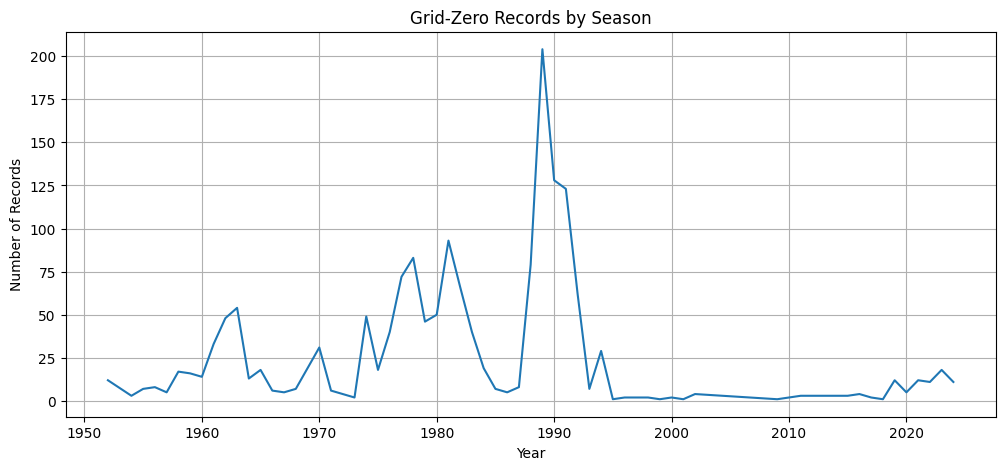

In [15]:
# Add year to grid-zero records
grid_zero_years = pd.merge(
    grid_zero,
    races[['raceId', 'year']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

# Calculate number of grid-zero records per year
grid_zero_counts = (
    grid_zero_years['year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

grid_zero_counts.plot()

plt.title('Grid-Zero Records by Season')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.grid(True)
plt.show()


#### 3.6.1 Investigating grid = 0 records

In [16]:
#Inspect the grid-zero drivers who finished
grid_zero_finished = grid_zero[
    grid_zero['status'].str.match(
        r'^(Finished|\+\d+ Laps?)$',
        na=False
    )
]

display(
    grid_zero_finished[
        ['raceId', 'driverId', 'grid',
         'positionOrder', 'status']
    ].head(20)
)

print(
    "Grid-zero records classified as finished/lapped:",
    len(grid_zero_finished)
)


,raceId,driverId,grid,positionOrder,status
1558,931,832,0,10,Finished
1569,1012,848,0,10,+1 Lap
1570,1013,8,0,10,+1 Lap
1571,1013,9,0,16,+2 Laps
1573,1014,807,0,13,Finished
1574,1016,825,0,17,+2 Laps
1575,1018,847,0,18,+2 Laps
1576,1022,9,0,17,+1 Lap
1577,1023,8,0,15,+1 Lap
1578,1025,848,0,5,Finished


Grid-zero records classified as finished/lapped: 56


In [17]:
# Exclude the three dominant non-starting status categories
other_grid_zero = grid_zero[
    ~grid_zero['status'].isin([
        'Did not qualify',
        'Did not prequalify',
        'Withdrew'
    ])
].copy()

print("Other grid-zero records:", len(other_grid_zero))

# Inspect completed laps and race classifications
display(
    other_grid_zero[
        ['raceId', 'driverId', 'grid', 'laps',
         'positionOrder', 'status']
    ].sort_values('laps', ascending=False).head(30)
)

print("Records with laps > 0:",
      (other_grid_zero['laps'] > 0).sum())

print("Records with laps = 0:",
      (other_grid_zero['laps'] == 0).sum())


Other grid-zero records: 130


,raceId,driverId,grid,laps,positionOrder,status
1558,931,832,0,78,10,Finished
1616,1111,825,0,72,16,Finished
1593,1064,815,0,71,8,+1 Lap
1632,1135,825,0,71,18,+1 Lap
1602,1084,822,0,70,11,+1 Lap
1635,1140,839,0,70,13,+1 Lap
1627,1129,822,0,70,13,Finished
1594,1064,849,0,70,16,+2 Laps
1613,1107,856,0,70,17,+1 Lap
1597,1071,8,0,70,12,+1 Lap


Records with laps > 0: 72
Records with laps = 0: 58


### 3.7 Qualifying coverage by season

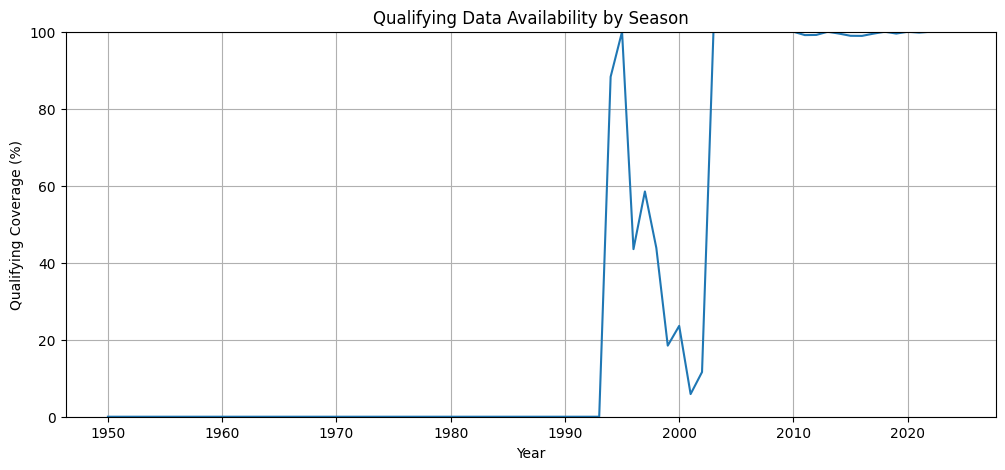

In [12]:
# Get race year for each result
results_years = pd.merge(
    results,
    races[['raceId', 'year']],
    on='raceId',
    how='left'
)

# Get unique driver-race combinations with qualifying data
qualifying_pairs = qualifying[
    ['raceId', 'driverId']
].drop_duplicates()

qualifying_pairs['has_qualifying'] = 1

# Match qualifying availability to result records
qualifying_coverage = pd.merge(
    results_years,
    qualifying_pairs,
    on=['raceId', 'driverId'],
    how='left'
)

# Missing match means no qualifying record
qualifying_coverage['has_qualifying'] = (
    qualifying_coverage['has_qualifying'].fillna(0)
)

# Percentage with qualifying data each year
coverage_by_year = (
    qualifying_coverage.groupby('year')['has_qualifying']
    .mean() * 100
)

plt.figure(figsize=(12, 5))
coverage_by_year.plot()

plt.title('Qualifying Data Availability by Season')
plt.xlabel('Year')
plt.ylabel('Qualifying Coverage (%)')
plt.ylim(0, 100)
plt.grid(True)
plt.show()


> Treat qualifying position as an optional additional feature and compare whether it improves model performance.

### 3.8 Data types and time formats
Conversions are first tried on temporary `*_check` copies to measure parse failures before cleaning.

In [19]:
# Inspect date and time-related columns

print("Races:")
print(races[['date', 'time']].dtypes)

print("\nQualifying:")
print(qualifying[['q1', 'q2', 'q3']].dtypes)

print("\nLap times:")
print(lap_times[['time', 'milliseconds']].dtypes)

print("\nPit stops:")
print(pit_stops[['time', 'duration', 'milliseconds']].dtypes)



display(races[['date', 'time']].head())

display(qualifying[['q1', 'q2', 'q3']].head())

display(lap_times[['time', 'milliseconds']].head())

display(pit_stops[['time', 'duration', 'milliseconds']].head())


Races:
date    object
time    object
dtype: object

Qualifying:
q1    object
q2    object
q3    object
dtype: object

Lap times:
time            object
milliseconds     int64
dtype: object

Pit stops:
time            object
duration        object
milliseconds     int64
dtype: object


,date,time
0,2009-03-29,06:00:00
1,2009-04-05,09:00:00
2,2009-04-19,07:00:00
3,2009-04-26,12:00:00
4,2009-05-10,12:00:00


,q1,q2,q3
0,1:26.572,1:25.187,1:26.714
1,1:26.103,1:25.315,1:26.869
2,1:25.664,1:25.452,1:27.079
3,1:25.994,1:25.691,1:27.178
4,1:25.960,1:25.518,1:27.236


,time,milliseconds
0,1:38.109,98109
1,1:33.006,93006
2,1:32.713,92713
3,1:32.803,92803
4,1:32.342,92342


,time,duration,milliseconds
0,17:05:23,26.898,26898
1,17:05:52,25.021,25021
2,17:20:48,23.426,23426
3,17:22:34,23.251,23251
4,17:24:10,23.842,23842


In [20]:
# Convert dates temporarily to check validity
race_dates_check = pd.to_datetime(
    races['date'],
    errors='coerce'
)

print("Original missing dates:", races['date'].isnull().sum())

print("Invalid dates after conversion:", race_dates_check.isnull().sum())

print("Earliest date:", race_dates_check.min())
print("Latest date:", race_dates_check.max())


Original missing dates: 0
Invalid dates after conversion: 0
Earliest date: 1950-05-13 00:00:00
Latest date: 2024-12-08 00:00:00


In [21]:
# Temporary copy for auditing
qualifying_check = qualifying.copy()

for column in ['q1', 'q2', 'q3']:

    # Convert qualifying lap time to timedelta
    converted = pd.to_timedelta(
        '00:' + qualifying_check[column].dropna().astype(str),
        errors='coerce'
    )

    # Store durations in seconds
    qualifying_check[column + '_seconds'] = np.nan

    qualifying_check.loc[
        converted.index,
        column + '_seconds'
    ] = converted.dt.total_seconds()

    print(column)
    print("Original non-missing:", qualifying[column].notna().sum())
    print("Successfully converted:", converted.notna().sum())
    print("Invalid formats:", converted.isna().sum())
    print("-" * 40)

display(
    qualifying_check[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)



# Work on a temporary copy
lap_times_check = lap_times.copy()

# Convert milliseconds to seconds
lap_times_check['time_seconds'] = (
    lap_times_check['milliseconds'] / 1000
)

# Display original and converted values
display(
    lap_times_check[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)



# Parse the original lap-time strings
parsed_lap_times = pd.to_timedelta(
    '00:' + lap_times['time'].astype(str),
    errors='coerce'
).dt.total_seconds()

# Compare parsed times with milliseconds
differences = (
    parsed_lap_times -
    lap_times_check['time_seconds']
).abs()

print("Unparseable lap times:", parsed_lap_times.isnull().sum())

print(
    "Time mismatches:",
    (differences > 0.001).sum()
)



pit_stops_check = pit_stops.copy()

# Convert duration strings to numeric seconds
pit_stops_check['duration_seconds'] = pd.to_numeric(
    pit_stops_check['duration'],
    errors='coerce'
)

# Convert milliseconds to seconds
pit_stops_check['milliseconds_seconds'] = (
    pit_stops_check['milliseconds'] / 1000
)

# Compare the two duration representations
differences = (
    pit_stops_check['duration_seconds'] -
    pit_stops_check['milliseconds_seconds']
).abs()

print(
    "Invalid duration strings:",
    pit_stops_check['duration_seconds'].isnull().sum()
)

print(
    "Duration mismatches:",
    (differences > 0.001).sum()
)

display(
    pit_stops_check[
        ['duration', 'milliseconds',
         'duration_seconds', 'milliseconds_seconds']
    ].head()
)


q1
Original non-missing: 10338
Successfully converted: 10338
Invalid formats: 0
----------------------------------------
q2
Original non-missing: 5847
Successfully converted: 5847
Invalid formats: 0
----------------------------------------
q3
Original non-missing: 3629
Successfully converted: 3629
Invalid formats: 0
----------------------------------------


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Unparseable lap times: 43
Time mismatches: 0
Invalid duration strings: 517
Duration mismatches: 0


,duration,milliseconds,duration_seconds,milliseconds_seconds
0,26.898,26898,26.898,26.898
1,25.021,25021,25.021,25.021
2,23.426,23426,23.426,23.426
3,23.251,23251,23.251,23.251
4,23.842,23842,23.842,23.842


In [23]:
invalid_pit_durations = pit_stops[
    pit_stops_check['duration_seconds'].isna() &
    pit_stops['duration'].notna()
]

print("Unparseable pit-stop durations:", len(invalid_pit_durations))

display(
    invalid_pit_durations[
        ['raceId', 'driverId', 'stop',
         'duration', 'milliseconds']
    ].head(30)
)

print(
    invalid_pit_durations['duration']
    .value_counts()
    .head(20)
)


Unparseable pit-stop durations: 517


,raceId,driverId,stop,duration,milliseconds
751,853,817,1,16:44.718,1004718
2419,881,814,2,2:03.124,123124
2420,881,16,2,1:29.401,89401
2421,881,18,3,1:44.833,104833
2422,884,16,1,1:14.026,74026
2533,888,17,1,2:42.042,162042
2713,893,154,3,1:13.009,73009
2802,894,16,3,1:11.445,71445
3089,901,817,3,1:49.329,109329
3159,903,13,1,1:18.277,78277


duration
24:16.349    2
2:03.124     1
6:29.973     1
6:32.517     1
6:33.601     1
6:36.504     1
6:36.837     1
6:41.057     1
6:41.749     1
6:42.478     1
6:40.857     1
6:40.463     1
6:42.029     1
6:46.256     1
6:47.553     1
6:47.673     1
6:27.399     1
50:11.861    1
51:05.174    1
51:09.017    1
Name: count, dtype: int64


In [24]:
# Lap-time milliseconds
print("Lap-time missing milliseconds:",
      lap_times['milliseconds'].isna().sum())

print("Lap-time non-positive milliseconds:",
      (lap_times['milliseconds'] <= 0).sum())

# Pit-stop milliseconds
print("Pit-stop missing milliseconds:",
      pit_stops['milliseconds'].isna().sum())

print("Pit-stop non-positive milliseconds:",
      (pit_stops['milliseconds'] <= 0).sum())

# Inspect the largest durations
display(
    lap_times.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'lap', 'time', 'milliseconds']
    ]
)

display(
    pit_stops.nlargest(10, 'milliseconds')[
        ['raceId', 'driverId', 'stop', 'duration', 'milliseconds']
    ]
)


Lap-time missing milliseconds: 0
Lap-time non-positive milliseconds: 0
Pit-stop missing milliseconds: 0
Pit-stop non-positive milliseconds: 0


,raceId,driverId,lap,time,milliseconds
8372,847,2,25,2:05:07.547,7507547
8020,847,13,25,2:05:06.656,7506656
8426,847,808,25,2:05:06.243,7506243
8621,847,155,25,2:05:06.095,7506095
7916,847,20,25,2:05:05.152,7505152
8089,847,17,25,2:05:05.034,7505034
7985,847,4,25,2:05:04.226,7504226
8495,847,814,25,2:05:03.980,7503980
8876,847,37,25,2:05:03.795,7503795
8234,847,18,25,2:05:03.775,7503775


,raceId,driverId,stop,duration,milliseconds
9156,1083,840,1,51:09.017,3069017
9155,1083,20,1,51:07.301,3067301
9157,1083,854,1,51:05.174,3065174
9154,1083,825,1,51:03.613,3063613
9152,1083,817,1,51:03.314,3063314
9151,1083,822,1,50:55.732,3055732
9147,1083,4,1,50:55.700,3055700
9150,1083,849,1,50:51.904,3051904
9153,1083,842,1,50:48.950,3048950
9145,1083,1,1,50:46.888,3046888


## 4. Data Cleaning
Raw tables are never modified; every cleaned table is a copy with the `_clean` suffix.

### 4.1 Create working copies

In [25]:
# Preserve original datasets: all cleaning happens on these copies
results_clean               = results.copy()
races_clean                 = races.copy()
drivers_clean               = drivers.copy()
constructors_clean          = constructors.copy()
qualifying_clean            = qualifying.copy()
status_clean                = status.copy()
circuits_clean              = circuits.copy()
constructor_results_clean   = constructor_results.copy()
constructor_standings_clean = constructor_standings.copy()
driver_standings_clean      = driver_standings.copy()
lap_times_clean             = lap_times.copy()
pit_stops_clean             = pit_stops.copy()
sprint_results_clean        = sprint_results.copy()
seasons_clean               = seasons.copy()

### 4.2 races_clean: race date

In [26]:
# Convert race dates to datetime
races_clean['date'] = pd.to_datetime(
    races_clean['date'],
    errors='coerce'
)

print(races_clean['date'].dtype)
print("Missing dates:", races_clean['date'].isnull().sum())


datetime64[ns]
Missing dates: 0


### 4.3 qualifying_clean: Q1–Q3 times to seconds

In [27]:
# Convert qualifying times into seconds
for column in ['q1', 'q2', 'q3']:

    converted = pd.to_timedelta(
        '00:' + qualifying_clean[column].dropna().astype(str),
        errors='coerce'
    )

    qualifying_clean[column + '_seconds'] = (
        converted.dt.total_seconds()
    )

display(
    qualifying_clean[
        ['q1', 'q1_seconds',
         'q2', 'q2_seconds',
         'q3', 'q3_seconds']
    ].head()
)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


### 4.4 lap_times_clean and pit_stops_clean: durations from milliseconds

In [28]:
# Convert milliseconds to seconds
lap_times_clean['time_seconds'] = (
    lap_times_clean['milliseconds'] / 1000
)

display(
    lap_times_clean[
        ['time', 'milliseconds', 'time_seconds']
    ].head()
)

print(
    "Missing converted lap times:",
    lap_times_clean['time_seconds'].isnull().sum()
)


,time,milliseconds,time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


Missing converted lap times: 0


In [29]:
# Convert pit-stop milliseconds to seconds
pit_stops_clean['duration_seconds'] = (
    pit_stops_clean['milliseconds'] / 1000
)

display(
    pit_stops_clean[
        ['duration', 'milliseconds', 'duration_seconds']
    ].head()
)

print(
    "Missing converted durations:",
    pit_stops_clean['duration_seconds'].isnull().sum()
)


,duration,milliseconds,duration_seconds
0,26.898,26898,26.898
1,25.021,25021,25.021
2,23.426,23426,23.426
3,23.251,23251,23.251
4,23.842,23842,23.842


Missing converted durations: 0


### 4.5 Validate conversions and row counts

In [30]:
# 1. Verify race dates
print("Race dates:")
print("Data type:", races_clean['date'].dtype)
print("Missing:", races_clean['date'].isna().sum())

# 2. Verify qualifying conversions
print("\nQualifying times:")

for column in ['q1', 'q2', 'q3']:
    failed = (
        qualifying_clean[column].notna() &
        qualifying_clean[column + '_seconds'].isna()
    ).sum()

    print(column, "- unexpected failures:", failed)

# 3. Verify lap and pit-stop durations
print("\nLap times:")
print(
    "Invalid durations:",
    (
        lap_times_clean['time_seconds'].isna() |
        (lap_times_clean['time_seconds'] <= 0)
    ).sum()
)

print("\nPit stops:")
print(
    "Invalid durations:",
    (
        pit_stops_clean['duration_seconds'].isna() |
        (pit_stops_clean['duration_seconds'] <= 0)
    ).sum()
)

# 4. Verify row counts have not changed
print("\nRow-count verification:")

for name, original, cleaned in [
    ('races', races, races_clean),
    ('qualifying', qualifying, qualifying_clean),
    ('lap_times', lap_times, lap_times_clean),
    ('pit_stops', pit_stops, pit_stops_clean)
]:
    print(
        name,
        "- original:", len(original),
        "- cleaned:", len(cleaned)
    )
    assert len(original) == len(cleaned)


Race dates:
Data type: datetime64[ns]
Missing: 0

Qualifying times:
q1 - unexpected failures: 0
q2 - unexpected failures: 0
q3 - unexpected failures: 0

Lap times:
Invalid durations: 0

Pit stops:
Invalid durations: 0

Row-count verification:
races - original: 1125 - cleaned: 1125
qualifying - original: 10494 - cleaned: 10494
lap_times - original: 589081 - cleaned: 589081
pit_stops - original: 11371 - cleaned: 11371


### 4.6 races_clean: structure and duplicate checks

In [42]:

# Inspect the cleaned races table
print("Dataset shape:", races_clean.shape)

print("\nColumn names:")
print(races_clean.columns.tolist())

print("\nData types:")
print(races_clean.dtypes)

print("\nFirst five rows:")
display(races_clean.head())

print("\nSummary statistics:")
display(races_clean.describe(include='all'))


Dataset shape: (1125, 18)

Column names:
['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

Data types:
raceId                  int64
year                    int64
round                   int64
circuitId               int64
name                   object
date           datetime64[ns]
time                   object
url                    object
fp1_date               object
fp1_time               object
fp2_date               object
fp2_time               object
fp3_date               object
fp3_time               object
quali_date             object
quali_time             object
sprint_date            object
sprint_time            object
dtype: object

First five rows:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Summary statistics:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
count,1125.000000,1125.000000,1125.000000,1125.000000,1125,1125,394,1125,90,68,90,68,72,53,90,68,18,15
unique,NaN,NaN,NaN,NaN,54,NaN,34,1125,90,20,90,19,72,18,90,15,18,12
top,NaN,NaN,NaN,NaN,Italian Grand Prix,NaN,12:00:00,https://en.wikipedia.org/wiki/2024_Abu_Dhabi_G...,2021-04-16,11:30:00,2021-04-16,15:00:00,2021-04-17,10:30:00,2021-04-17,14:00:00,2021-07-17,14:30:00
freq,NaN,NaN,NaN,NaN,75,NaN,113,1,1,18,1,22,1,14,1,24,1,4
mean,565.710222,1992.703111,8.579556,23.889778,NaN,1993-03-25 13:23:50.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1950.000000,1.000000,1.000000,NaN,1950-05-13 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,282.000000,1977.000000,4.000000,9.000000,NaN,1977-01-23 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,563.000000,1994.000000,8.000000,18.000000,NaN,1994-11-06 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,845.000000,2011.000000,13.000000,34.000000,NaN,2011-05-22 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,1144.000000,2024.000000,24.000000,80.000000,NaN,2024-12-08 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:

print("Exact duplicate rows:",
      races_clean.duplicated().sum())

print("Missing race IDs:",
      races_clean['raceId'].isna().sum())

print("Duplicate race IDs:",
      races_clean['raceId'].duplicated().sum())

print("Duplicate year-round combinations:",
      races_clean.duplicated(
          subset=['year', 'round']
      ).sum())

# Show repeated year-round combinations, if any
duplicate_races = races_clean[
    races_clean.duplicated(
        subset=['year', 'round'],
        keep=False
    )
]

display(
    duplicate_races[
        ['raceId', 'year', 'round', 'name', 'date']
    ].sort_values(['year', 'round'])
)


Exact duplicate rows: 0
Missing race IDs: 0
Duplicate race IDs: 0
Duplicate year-round combinations: 0


,raceId,year,round,name,date


#### 4.6.1 Session dates and times

In [44]:

# Convert optional session dates to datetime
date_columns = [
    'fp1_date',
    'fp2_date',
    'fp3_date',
    'quali_date',
    'sprint_date'
]

# Record original non-missing counts
original_date_counts = races_clean[date_columns].notna().sum()

for col in date_columns:
    races_clean[col] = pd.to_datetime(
        races_clean[col],
        errors='coerce'
    )

# Check whether valid values were lost
converted_date_counts = races_clean[date_columns].notna().sum()

date_validation = pd.DataFrame({
    'Before': original_date_counts,
    'After': converted_date_counts,
    'Failed Conversions': (
        original_date_counts - converted_date_counts
    )
})

display(date_validation)
print(races_clean[date_columns].dtypes)


,Before,After,Failed Conversions
fp1_date,90,90,0
fp2_date,90,90,0
fp3_date,72,72,0
quali_date,90,90,0
sprint_date,18,18,0


fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object


In [45]:

# Convert clock-time columns
time_columns = [
    'time',
    'fp1_time',
    'fp2_time',
    'fp3_time',
    'quali_time',
    'sprint_time'
]

original_time_counts = races_clean[time_columns].notna().sum()

for col in time_columns:
    parsed = pd.to_datetime(
        races_clean[col],
        format='%H:%M:%S',
        errors='coerce'
    )

    races_clean[col] = parsed.dt.time

converted_time_counts = races_clean[time_columns].notna().sum()

time_validation = pd.DataFrame({
    'Before': original_time_counts,
    'After': converted_time_counts,
    'Failed Conversions': (
        original_time_counts - converted_time_counts
    )
})

display(time_validation)


,Before,After,Failed Conversions
time,394,394,0
fp1_time,68,68,0
fp2_time,68,68,0
fp3_time,53,53,0
quali_time,68,68,0
sprint_time,15,15,0


In [46]:

print("Date column types:")
print(races_clean[['date'] + date_columns].dtypes)

print("\nSample converted dates and times:")

display(
    races_clean.loc[
        races_clean['fp1_date'].notna(),
        [
            'year', 'name', 'date', 'time',
            'fp1_date', 'fp1_time',
            'quali_date', 'quali_time'
        ]
    ].head(10)
)

# Ensure no originally populated values were lost
assert (date_validation['Failed Conversions'] == 0).all()
assert (time_validation['Failed Conversions'] == 0).all()

print("\nAll date and time conversions validated!")


Date column types:
date           datetime64[ns]
fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object

Sample converted dates and times:


,year,name,date,time,fp1_date,fp1_time,quali_date,quali_time
1035,2021,Emilia Romagna Grand Prix,2021-04-18,13:00:00,2021-04-16,NaT,2021-04-17,NaT
1036,2022,Bahrain Grand Prix,2022-03-20,15:00:00,2022-03-18,12:00:00,2022-03-19,15:00:00
1037,2021,Bahrain Grand Prix,2021-03-28,15:00:00,2021-03-26,NaT,2021-03-27,NaT
1038,2021,Qatar Grand Prix,2021-11-21,14:00:00,2021-11-19,NaT,2021-11-20,NaT
1039,2021,Portuguese Grand Prix,2021-05-02,14:00:00,2021-04-30,NaT,2021-05-01,NaT
1040,2021,Spanish Grand Prix,2021-05-09,13:00:00,2021-05-07,NaT,2021-05-08,NaT
1041,2021,Monaco Grand Prix,2021-05-23,13:00:00,2021-05-21,NaT,2021-05-22,NaT
1042,2021,Azerbaijan Grand Prix,2021-06-06,12:00:00,2021-06-04,NaT,2021-06-05,NaT
1043,2021,Styrian Grand Prix,2021-06-27,13:00:00,2021-06-25,NaT,2021-06-26,NaT
1044,2021,French Grand Prix,2021-06-20,13:00:00,2021-06-18,NaT,2021-06-19,NaT



All date and time conversions validated!


#### 4.6.2 Schedule missingness by season

In [47]:

# Count missing values after type conversion
missing_counts = races_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': (
        missing_counts / len(races_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing %',
        ascending=False
    )
)


,Missing Count,Missing %
sprint_time,1110,98.67
sprint_date,1107,98.40
fp3_time,1072,95.29
quali_time,1057,93.96
fp2_time,1057,93.96
fp1_time,1057,93.96
fp3_date,1053,93.60
fp2_date,1035,92.00
fp1_date,1035,92.00
quali_date,1035,92.00


In [48]:

schedule_columns = [
    'time',
    'fp1_date', 'fp1_time',
    'fp2_date', 'fp2_time',
    'fp3_date', 'fp3_time',
    'quali_date', 'quali_time',
    'sprint_date', 'sprint_time'
]

# Calculate non-missing percentage for every season
schedule_availability = (
    races_clean
    .groupby('year')[schedule_columns]
    .agg(lambda x: x.notna().mean() * 100)
)

# Display the most recent seasons
display(
    schedule_availability.tail(15).round(2)
)


,time,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
year,,,,,,,,,,,
2010,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2011,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2012,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2013,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2014,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2015,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2016,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2017,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00
2018,100.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00


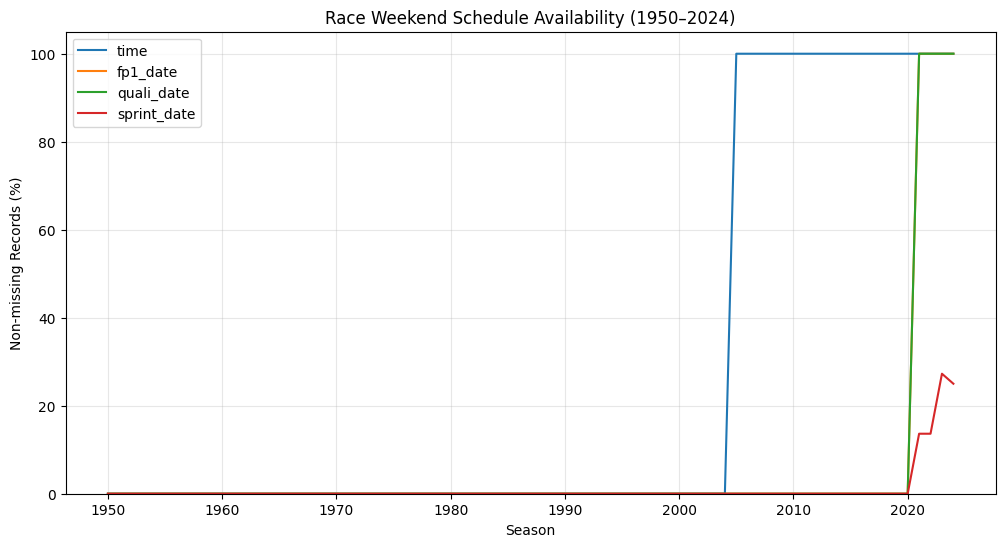

In [49]:

plt.figure(figsize=(12, 6))

for column in [
    'time',
    'fp1_date',
    'quali_date',
    'sprint_date'
]:
    plt.plot(
        schedule_availability.index,
        schedule_availability[column],
        label=column
    )

plt.title('Race Weekend Schedule Availability (1950–2024)')
plt.xlabel('Season')
plt.ylabel('Non-missing Records (%)')

plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)

plt.show()


**Decision: schedule NaNs are kept, not filled.**
- They are structurally missing, not errors: practice/qualifying dates are only recorded from 2021 (times from 2022), sprint columns exist only at sprint weekends, and race start `time` only in recent seasons.
- No other table holds these values (`qualifying` and `sprint_results` have no dates), so they cannot be recovered; filling them would invent data and turn the datetime columns back into text.
- These columns are not model features, so NaN is the correct representation.

#### 4.6.3 Date consistency checks

In [50]:

# Check that each race date belongs to its recorded season
year_mismatches = races_clean[
    races_clean['date'].dt.year != races_clean['year']
]

print(
    "Race dates outside their recorded season:",
    len(year_mismatches)
)

display(
    year_mismatches[
        ['raceId', 'year', 'round', 'name', 'date']
    ]
)


Race dates outside their recorded season: 0


,raceId,year,round,name,date


In [51]:

# Sort races within each season by championship round
races_ordered = races_clean.sort_values(
    ['year', 'round']
).copy()

# Previous round's race date
races_ordered['previous_date'] = (
    races_ordered.groupby('year')['date'].shift(1)
)

# Identify races scheduled before the preceding round
round_date_issues = races_ordered[
    races_ordered['previous_date'].notna()
    & (races_ordered['date'] < races_ordered['previous_date'])
]

print(
    "Races earlier than the previous round:",
    len(round_date_issues)
)

display(
    round_date_issues[
        ['raceId', 'year', 'round',
         'name', 'date', 'previous_date']
    ]
)


Races earlier than the previous round: 0


,raceId,year,round,name,date,previous_date


In [52]:

session_date_columns = [
    'fp1_date',
    'fp2_date',
    'fp3_date',
    'quali_date',
    'sprint_date'
]

for col in session_date_columns:

    issues = races_clean[
        races_clean[col].notna()
        & (races_clean[col] > races_clean['date'])
    ]

    print(f"{col}: {len(issues)} dates after race day")

    if not issues.empty:
        display(
            issues[
                ['raceId', 'year', 'name',
                 'date', col]
            ]
        )


fp1_date: 0 dates after race day
fp2_date: 0 dates after race day
fp3_date: 0 dates after race day
quali_date: 0 dates after race day
sprint_date: 0 dates after race day


### 4.7 qualifying_clean: integrity and missing values

In [53]:

# Check qualifying record integrity
print("Original shape:", qualifying.shape)
print("Cleaned shape:", qualifying_clean.shape)

print("\nExact duplicate rows:",
      qualifying_clean.duplicated().sum())

print("Missing qualify IDs:",
      qualifying_clean['qualifyId'].isna().sum())

print("Duplicate qualify IDs:",
      qualifying_clean['qualifyId'].duplicated().sum())

print("Duplicate race-driver combinations:",
      qualifying_clean.duplicated(
          subset=['raceId', 'driverId']
      ).sum())

# Display any duplicated race-driver entries
duplicate_qualifying = qualifying_clean[
    qualifying_clean.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].sort_values(['raceId', 'driverId'])

display(
    duplicate_qualifying[
        [
            'qualifyId', 'raceId', 'driverId',
            'constructorId', 'number', 'position',
            'q1', 'q2', 'q3'
        ]
    ]
)


Original shape: (10494, 9)
Cleaned shape: (10494, 12)

Exact duplicate rows: 0
Missing qualify IDs: 0
Duplicate qualify IDs: 0
Duplicate race-driver combinations: 0


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3


In [54]:

missing = qualifying_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (
        missing / len(qualifying_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing Count',
        ascending=False
    )
)


,Missing Count,Missing %
q3_seconds,6865,65.42
q3,6865,65.42
q2_seconds,4647,44.28
q2,4647,44.28
q1,156,1.49
q1_seconds,156,1.49


#### 4.7.1 Session-time patterns

In [55]:

# Add race, driver and constructor information for inspection
qualifying_inspection = (
    qualifying_clean
    .merge(
        races_clean[['raceId', 'year', 'round', 'name']],
        on='raceId',
        how='left'
    )
    .merge(
        drivers[['driverId', 'forename', 'surname']],
        on='driverId',
        how='left'
    )
    .merge(
        constructors[['constructorId', 'name']],
        on='constructorId',
        how='left',
        suffixes=('_race', '_constructor')
    )
)

# Select readable columns
inspection_columns = [
    'year', 'round', 'name_race',
    'forename', 'surname', 'name_constructor',
    'number', 'position',
    'q1', 'q2', 'q3',
    'q1_seconds', 'q2_seconds', 'q3_seconds'
]

display(
    qualifying_inspection[inspection_columns].head(20)
)


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,2008,1,Australian Grand Prix,Lewis,Hamilton,McLaren,22,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,2008,1,Australian Grand Prix,Robert,Kubica,BMW Sauber,4,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,2008,1,Australian Grand Prix,Heikki,Kovalainen,McLaren,23,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079
3,2008,1,Australian Grand Prix,Felipe,Massa,Ferrari,2,4,1:25.994,1:25.691,1:27.178,85.994,85.691,87.178
4,2008,1,Australian Grand Prix,Nick,Heidfeld,BMW Sauber,3,5,1:25.960,1:25.518,1:27.236,85.960,85.518,87.236
5,2008,1,Australian Grand Prix,Jarno,Trulli,Toyota,11,6,1:26.427,1:26.101,1:28.527,86.427,86.101,88.527
6,2008,1,Australian Grand Prix,Nico,Rosberg,Williams,7,7,1:26.295,1:26.059,1:28.687,86.295,86.059,88.687
7,2008,1,Australian Grand Prix,David,Coulthard,Red Bull,9,8,1:26.381,1:26.063,1:29.041,86.381,86.063,89.041
8,2008,1,Australian Grand Prix,Timo,Glock,Toyota,12,9,1:26.919,1:26.164,1:29.593,86.919,86.164,89.593
9,2008,1,Australian Grand Prix,Sebastian,Vettel,Toro Rosso,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN


In [56]:

# Drivers with all three session times
all_sessions = qualifying_inspection[
    qualifying_inspection[
        ['q1', 'q2', 'q3']
    ].notna().all(axis=1)
]

# Drivers with Q1 and Q2, but no Q3
q1_q2_only = qualifying_inspection[
    qualifying_inspection['q1'].notna()
    & qualifying_inspection['q2'].notna()
    & qualifying_inspection['q3'].isna()
]

# Drivers with only Q1 recorded
q1_only = qualifying_inspection[
    qualifying_inspection['q1'].notna()
    & qualifying_inspection['q2'].isna()
    & qualifying_inspection['q3'].isna()
]

# Drivers with no Q1 time
missing_q1 = qualifying_inspection[
    qualifying_inspection['q1'].isna()
]

print("All Q1, Q2, Q3 recorded:", len(all_sessions))
print("Q1 and Q2 only:", len(q1_q2_only))
print("Q1 only:", len(q1_only))
print("Missing Q1:", len(missing_q1))

print("\nExample: all three sessions")
display(all_sessions[inspection_columns].head(5))

print("\nExample: Q1 and Q2 only")
display(q1_q2_only[inspection_columns].head(5))

print("\nExample: Q1 only")
display(q1_only[inspection_columns].head(5))

print("\nExample: missing Q1")
display(missing_q1[inspection_columns].head(10))


All Q1, Q2, Q3 recorded: 3629
Q1 and Q2 only: 2218
Q1 only: 4491
Missing Q1: 156

Example: all three sessions


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,2008,1,Australian Grand Prix,Lewis,Hamilton,McLaren,22,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,2008,1,Australian Grand Prix,Robert,Kubica,BMW Sauber,4,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,2008,1,Australian Grand Prix,Heikki,Kovalainen,McLaren,23,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079
3,2008,1,Australian Grand Prix,Felipe,Massa,Ferrari,2,4,1:25.994,1:25.691,1:27.178,85.994,85.691,87.178
4,2008,1,Australian Grand Prix,Nick,Heidfeld,BMW Sauber,3,5,1:25.960,1:25.518,1:27.236,85.960,85.518,87.236



Example: Q1 and Q2 only


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
9,2008,1,Australian Grand Prix,Sebastian,Vettel,Toro Rosso,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN
10,2008,1,Australian Grand Prix,Rubens,Barrichello,Honda,17,11,1:26.369,1:26.173,NaN,86.369,86.173,NaN
11,2008,1,Australian Grand Prix,Fernando,Alonso,Renault,5,12,1:26.907,1:26.188,NaN,86.907,86.188,NaN
12,2008,1,Australian Grand Prix,Jenson,Button,Honda,16,13,1:26.712,1:26.259,NaN,86.712,86.259,NaN
13,2008,1,Australian Grand Prix,Kazuki,Nakajima,Williams,8,14,1:26.891,1:26.413,NaN,86.891,86.413,NaN



Example: Q1 only


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
14,2008,1,Australian Grand Prix,Mark,Webber,Red Bull,10,15,1:26.914,NaN,NaN,86.914,NaN,NaN
15,2008,1,Australian Grand Prix,Kimi,Räikkönen,Ferrari,1,16,1:26.140,NaN,NaN,86.140,NaN,NaN
16,2008,1,Australian Grand Prix,Giancarlo,Fisichella,Force India,21,17,1:27.207,NaN,NaN,87.207,NaN,NaN
17,2008,1,Australian Grand Prix,Sébastien,Bourdais,Toro Rosso,14,18,1:27.446,NaN,NaN,87.446,NaN,NaN
18,2008,1,Australian Grand Prix,Adrian,Sutil,Force India,20,19,1:27.859,NaN,NaN,87.859,NaN,NaN



Example: missing Q1


,year,round,name_race,forename,surname,name_constructor,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
147,2008,7,Canadian Grand Prix,Sebastian,Vettel,Toro Rosso,15,20,NaN,NaN,NaN,NaN,NaN,NaN
307,2008,15,Singapore Grand Prix,Giancarlo,Fisichella,Force India,21,20,NaN,NaN,NaN,NaN,NaN,NaN
455,2007,4,Spanish Grand Prix,Scott,Speed,Toro Rosso,19,22,NaN,NaN,NaN,NaN,NaN,NaN
477,2007,5,Monaco Grand Prix,Christijan,Albers,Spyker,21,22,NaN,NaN,NaN,NaN,NaN,NaN
763,2006,1,Bahrain Grand Prix,Kimi,Räikkönen,McLaren,3,22,NaN,NaN,NaN,NaN,NaN,NaN
873,2006,6,Spanish Grand Prix,David,Coulthard,Red Bull,14,22,NaN,NaN,NaN,NaN,NaN,NaN
894,2006,7,Monaco Grand Prix,Felipe,Massa,Ferrari,6,21,NaN,NaN,NaN,NaN,NaN,NaN
895,2006,7,Monaco Grand Prix,Michael,Schumacher,Ferrari,5,22,NaN,NaN,NaN,NaN,NaN,NaN
917,2006,8,British Grand Prix,Jarno,Trulli,Toyota,8,22,NaN,NaN,NaN,NaN,NaN,NaN
1005,2006,12,German Grand Prix,Scott,Speed,Toro Rosso,21,22,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:

# Select a specific race
selected_race = qualifying_inspection[
    (qualifying_inspection['year'] == 2024)
    & (qualifying_inspection['name_race'] == 'Bahrain Grand Prix')
].sort_values('position')

display(
    selected_race[
        [
            'position', 'forename', 'surname',
            'name_constructor', 'number',
            'q1', 'q2', 'q3',
            'q1_seconds', 'q2_seconds', 'q3_seconds'
        ]
    ]
)


,position,forename,surname,name_constructor,number,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
10015,1,Max,Verstappen,Red Bull,1,1:30.031,1:29.374,1:29.179,90.031,89.374,89.179
10016,2,Charles,Leclerc,Ferrari,16,1:30.243,1:29.165,1:29.407,90.243,89.165,89.407
10017,3,George,Russell,Mercedes,63,1:30.350,1:29.922,1:29.485,90.350,89.922,89.485
10018,4,Carlos,Sainz,Ferrari,55,1:29.909,1:29.573,1:29.507,89.909,89.573,89.507
10019,5,Sergio,Pérez,Red Bull,11,1:30.221,1:29.932,1:29.537,90.221,89.932,89.537
10020,6,Fernando,Alonso,Aston Martin,14,1:30.179,1:29.801,1:29.542,90.179,89.801,89.542
10021,7,Lando,Norris,McLaren,4,1:30.143,1:29.941,1:29.614,90.143,89.941,89.614
10022,8,Oscar,Piastri,McLaren,81,1:30.531,1:30.122,1:29.683,90.531,90.122,89.683
10023,9,Lewis,Hamilton,Mercedes,44,1:30.451,1:29.718,1:29.710,90.451,89.718,89.710
10024,10,Nico,Hülkenberg,Haas F1 Team,27,1:30.566,1:29.851,1:30.502,90.566,89.851,90.502


#### 4.7.2 Label missing session times
Only the string columns get labels; the numeric `*_seconds` columns keep NaN on purpose.
Knockout qualifying (Q1/Q2/Q3) started in 2006, so missing Q2/Q3 before 2006 is labelled as a single-session format, not an elimination.

In [58]:
# Determine which sessions have recorded lap times
has_q1 = qualifying_clean['q1_seconds'].notna()
has_q2 = qualifying_clean['q2_seconds'].notna()
has_q3 = qualifying_clean['q3_seconds'].notna()

# Pattern 1: Q1 and Q2 recorded, Q3 missing
q2_only_end = has_q1 & has_q2 & ~has_q3

# Pattern 2: Only Q1 recorded
q1_only_end = has_q1 & ~has_q2 & ~has_q3

# Pattern 3: No qualifying session times recorded
no_times = ~has_q1 & ~has_q2 & ~has_q3

# Knockout format (Q1/Q2/Q3) only exists from 2006
qualifying_year = qualifying_clean['raceId'].map(
    races_clean.set_index('raceId')['year']
)
knockout_era = qualifying_year >= 2006

# Evidence: no Q2/Q3 times exist before 2006
print("Pre-2006 rows with a Q2 or Q3 time:",
      (~knockout_era & (has_q2 | has_q3)).sum())

# Fill only missing values in the original string columns
qualifying_clean.loc[q2_only_end, 'q3'] = (
    'Not Recorded After Q2'
)

qualifying_clean.loc[q1_only_end & knockout_era, ['q2', 'q3']] = (
    'Not Recorded After Q1'
)

qualifying_clean.loc[q1_only_end & ~knockout_era, ['q2', 'q3']] = (
    'Single-session format'
)

qualifying_clean.loc[no_times, ['q1', 'q2', 'q3']] = (
    'No Qualifying Time Recorded'
)

# Check how many missing values remain
print("Missing descriptive fields:")
print(qualifying_clean[['q1', 'q2', 'q3']].isna().sum())

print("\nNumeric time missingness (intentionally preserved):")
print(
    qualifying_clean[
        ['q1_seconds', 'q2_seconds', 'q3_seconds']
    ].isna().sum()
)


Missing descriptive fields:
q1    0
q2    0
q3    0
dtype: int64

Numeric time missingness (intentionally preserved):
q1_seconds     156
q2_seconds    4647
q3_seconds    6865
dtype: int64


In [ ]:

print("Q1 values:")
display(qualifying_clean['q1'].value_counts(dropna=False).head(10))

print("\nQ2 labels:")
print(
    qualifying_clean['q2']
    .value_counts(dropna=False)
    .loc[lambda x: x.index.isin([
        'Not Recorded After Q1',
        'Single-session format',
        'No Qualifying Time Recorded'
    ])]
)

print("\nQ3 labels:")
print(
    qualifying_clean['q3']
    .value_counts(dropna=False)
    .loc[lambda x: x.index.isin([
        'Not Recorded After Q1',
        'Not Recorded After Q2',
        'Single-session format',
        'No Qualifying Time Recorded'
    ])]
)

display(
    qualifying_clean[
        ['raceId', 'driverId', 'position',
         'q1', 'q2', 'q3',
         'q1_seconds', 'q2_seconds', 'q3_seconds']
    ].head(15)
)


: 

### 4.8 results_clean: missing car numbers

In [31]:
# Find all result rows with missing car numbers
missing_numbers = results[
    results['number'].isna()
].copy()

# Identify all rows belonging to duplicate driver-race groups
duplicate_pairs = results.loc[
    results.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    ),
    ['raceId', 'driverId']
].drop_duplicates()

# Check which missing-number records belong to duplicate groups
missing_numbers = missing_numbers.merge(
    duplicate_pairs.assign(in_duplicate_group=True),
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

missing_numbers['in_duplicate_group'] = (
    missing_numbers['in_duplicate_group']
    .fillna(False)
    .astype(bool)
)

display(
    missing_numbers[
        ['raceId', 'driverId', 'constructorId',
         'number', 'grid', 'positionOrder',
         'in_duplicate_group']
    ]
)

print("Total missing car numbers:", len(missing_numbers))

print(
    "Missing-number rows in duplicate groups:",
    missing_numbers['in_duplicate_group'].sum()
)


/tmp/ipykernel_16/240946227.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,raceId,driverId,constructorId,number,grid,positionOrder,in_duplicate_group
0,732,459,66,NaN,0,19,False
1,732,462,95,NaN,0,20,False
2,732,446,172,NaN,0,21,False
3,732,437,170,NaN,0,22,False
4,741,485,172,NaN,0,28,False
5,728,305,26,NaN,0,23,False


Total missing car numbers: 6
Missing-number rows in duplicate groups: 0


In [32]:
# Start with the six records with missing car numbers
missing_numbers_details = results[
    results['number'].isna()
].copy()

# Add race status descriptions
missing_numbers_details = missing_numbers_details.merge(
    status[['statusId', 'status']],
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Add race information
missing_numbers_details = missing_numbers_details.merge(
    races[['raceId', 'year', 'name', 'date']],
    on='raceId',
    how='left',
    validate='many_to_one'
)

# Display relevant information
display(
    missing_numbers_details[
        ['year', 'name', 'driverId',
         'constructorId', 'number', 'grid',
         'laps', 'positionOrder', 'status']
    ].sort_values('year')
)


,year,name,driverId,constructorId,number,grid,laps,positionOrder,status
4,1961,French Grand Prix,485,172,NaN,0,0,28,Withdrew
0,1962,French Grand Prix,459,66,NaN,0,0,19,Withdrew
2,1962,French Grand Prix,446,172,NaN,0,0,21,Withdrew
1,1962,French Grand Prix,462,95,NaN,0,0,20,Withdrew
3,1962,French Grand Prix,437,170,NaN,0,0,22,Withdrew
5,1963,South African Grand Prix,305,26,NaN,0,0,23,Withdrew


In [33]:
# Identify the six records with missing car numbers
rows_to_remove = results_clean['number'].isna()

print("Records to remove:", rows_to_remove.sum())

# Remove the six records
results_clean = results_clean.loc[~rows_to_remove].copy()

# Verify the cleaning
print("Original rows:", len(results))
print("Cleaned rows:", len(results_clean))
print("Remaining missing car numbers:",
      results_clean['number'].isna().sum())

assert len(results_clean) == len(results) - 6
assert results_clean['number'].isna().sum() == 0


Records to remove: 6
Original rows: 26759
Cleaned rows: 26753
Remaining missing car numbers: 0


### 4.9 constructor_results_clean: `status` column

In [34]:
# Display the first 10 rows
display(constructor_results.head(10))

# Check number of rows and columns
print("Dataset shape:", constructor_results.shape)

# Display column names
print("\nColumn names:")
print(constructor_results.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
constructor_results.info()


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN
5,6,18,6,1.0,NaN
6,7,18,7,0.0,NaN
7,8,18,8,0.0,NaN
8,9,18,9,0.0,NaN
9,10,18,10,0.0,NaN


Dataset shape: (12625, 5)

Column names:
['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [35]:
# Show frequency of each status value
print("Status value distribution:")
print(
    constructor_results['status']
    .value_counts(dropna=False)
)

# Display rows with available status
print("\nRecords with non-missing status:")

display(
    constructor_results[
        constructor_results['status'].notna()
    ]
)


Status value distribution:
status
NaN    12608
D         17
Name: count, dtype: int64

Records with non-missing status:


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [36]:
# Verify which constructor and season have status = D
status_details = (
    constructor_results[
        constructor_results['status'].notna()
    ]
    .merge(
        constructors[['constructorId', 'name']],
        on='constructorId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        races[['raceId', 'year']],
        on='raceId',
        how='left',
        validate='many_to_one'
    )
)

display(
    status_details[
        ['year', 'name', 'raceId', 'points', 'status']
    ]
)

# Drop the mostly-empty status column
constructor_results_clean = (
    constructor_results_clean.drop(columns=['status'])
)

print("Original shape:", constructor_results.shape)
print("Cleaned shape:", constructor_results_clean.shape)
print("Remaining missing values:")
print(constructor_results_clean.isna().sum())

assert len(constructor_results_clean) == len(constructor_results)


,year,name,raceId,points,status
0,2007,McLaren,36,14.0,D
1,2007,McLaren,37,18.0,D
2,2007,McLaren,38,12.0,D
3,2007,McLaren,39,14.0,D
4,2007,McLaren,40,18.0,D
5,2007,McLaren,41,12.0,D
6,2007,McLaren,42,18.0,D
7,2007,McLaren,43,8.0,D
8,2007,McLaren,44,14.0,D
9,2007,McLaren,45,10.0,D


Original shape: (12625, 5)
Cleaned shape: (12625, 4)
Remaining missing values:
constructorResultsId    0
raceId                  0
constructorId           0
points                  0
dtype: int64


### 4.10 drivers_clean: missing codes and duplicate names

In [37]:
# Display missing counts
print("Missing driver numbers:",
      drivers['number'].isna().sum())

print("Missing driver codes:",
      drivers['code'].isna().sum())

# Inspect examples
display(
    drivers[
        drivers['number'].isna() |
        drivers['code'].isna()
    ][
        ['driverId', 'forename', 'surname',
         'number', 'code']
    ].head(20)
)

# Check whether stable driver IDs are complete
print(
    "Missing driver IDs:",
    drivers['driverId'].isna().sum()
)

print(
    "Duplicate driver IDs:",
    drivers['driverId'].duplicated().sum()
)


Missing driver numbers: 802
Missing driver codes: 757


,driverId,forename,surname,number,code
1,2,Nick,Heidfeld,NaN,HEI
4,5,Heikki,Kovalainen,NaN,KOV
5,6,Kazuki,Nakajima,NaN,NAK
6,7,Sébastien,Bourdais,NaN,BOU
9,10,Timo,Glock,NaN,GLO
10,11,Takuma,Sato,NaN,SAT
11,12,Nelson,Piquet Jr.,NaN,PIQ
13,14,David,Coulthard,NaN,COU
14,15,Jarno,Trulli,NaN,TRU
16,17,Mark,Webber,NaN,WEB


Missing driver IDs: 0
Duplicate driver IDs: 0


**Decision: missing `drivers.number` is not filled.**
- `drivers.number` is the driver's permanent racing number, introduced in 2014, so most earlier drivers never had one; it is structurally missing (802 rows), not an error.
- The car number a driver used in each race is stored per race in `results.number` (and `qualifying.number`), so that is the column we rely on; `drivers.number` is not used as a feature.

In [38]:
# 1. Check completely identical rows
print("Exact duplicate rows:", drivers.duplicated().sum())

# 2. Check duplicate driver IDs (primary key)
print(
    "Duplicate driver IDs:",
    drivers.duplicated(subset=['driverId']).sum()
)

# 3. Check drivers with identical first and last names
print(
    "Duplicate full names:",
    drivers.duplicated(
        subset=['forename', 'surname']
    ).sum()
)

# 4. Display all records sharing the same full name
duplicate_names = drivers[
    drivers.duplicated(
        subset=['forename', 'surname'],
        keep=False
    )
].sort_values(['forename', 'surname'])

display(
    duplicate_names[
        ['driverId', 'forename', 'surname',
         'dob', 'nationality', 'number', 'code']
    ]
)


Exact duplicate rows: 0
Duplicate driver IDs: 0
Duplicate full names: 0


,driverId,forename,surname,dob,nationality,number,code


In [39]:

# Work only with drivers whose official code is available
code_check = drivers[
    drivers['code'].notna()
].copy()

# Generate the first three letters of each surname
code_check['generated_code'] = (
    code_check['surname']
    .str[:3]
    .str.upper()
)

# Compare generated codes with recorded codes
code_check['code_matches'] = (
    code_check['generated_code'] == code_check['code']
)

print("Drivers with recorded codes:", len(code_check))

print(
    "Matching codes:",
    code_check['code_matches'].sum()
)

print(
    "Mismatching codes:",
    (~code_check['code_matches']).sum()
)

print(
    "Match percentage:",
    round(code_check['code_matches'].mean() * 100, 2),
    "%"
)

# Display exceptions
display(
    code_check.loc[
        ~code_check['code_matches'],
        ['driverId', 'forename', 'surname',
         'code', 'generated_code']
    ]
)


Drivers with recorded codes: 104
Matching codes: 89
Mismatching codes: 15
Match percentage: 85.58 %


,driverId,forename,surname,code,generated_code
7,8,Kimi,Räikkönen,RAI,RÄI
29,30,Michael,Schumacher,MSC,SCH
30,31,Juan,Pablo Montoya,MON,PAB
32,33,Tiago,Monteiro,TMO,MON
35,36,Franck,Montagny,FMO,MON
36,37,Pedro,de la Rosa,DLR,DE
807,807,Nico,Hülkenberg,HUL,HÜL
809,810,Lucas,di Grassi,DIG,DI
813,814,Paul,di Resta,DIR,DI
814,815,Sergio,Pérez,PER,PÉR


In [40]:
# Generate a three-letter surname abbreviation
generated_codes = (
    drivers_clean['surname']
    .str[:3]
    .str.upper()
)

# Track whether each code was generated
drivers_clean['code_was_generated'] = (
    drivers_clean['code'].isna()
)

# Fill only missing codes
drivers_clean['code_filled'] = (
    drivers_clean['code'].fillna(generated_codes)
)

# Verify that existing official codes were not changed
assert (
    drivers_clean.loc[
        drivers_clean['code'].notna(), 'code'
    ].equals(
        drivers_clean.loc[
            drivers_clean['code'].notna(), 'code_filled'
        ]
    )
)

print(
    "Existing codes preserved:",
    drivers_clean['code'].notna().sum()
)

print(
    "Generated abbreviations:",
    drivers_clean['code_was_generated'].sum()
)

print(
    "Remaining missing abbreviations:",
    drivers_clean['code_filled'].isna().sum()
)


Existing codes preserved: 104
Generated abbreviations: 757
Remaining missing abbreviations: 0


In [41]:

# Check final table structure
print("Original shape:", drivers.shape)
print("Cleaned shape:", drivers_clean.shape)

# Verify unique and complete IDs
print("\nMissing driver IDs:",
      drivers_clean['driverId'].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean['driverId'].duplicated().sum())

print("Exact duplicate rows:",
      drivers_clean.duplicated().sum())

# Verify generated code column
print("\nMissing original codes:",
      drivers_clean['code'].isna().sum())

print("Missing completed codes:",
      drivers_clean['code_filled'].isna().sum())

print("Generated abbreviations:",
      drivers_clean['code_was_generated'].sum())

# Check that existing codes were preserved
existing = drivers_clean['code'].notna()

print(
    "Existing codes changed:",
    (
        drivers_clean.loc[existing, 'code'] !=
        drivers_clean.loc[existing, 'code_filled']
    ).sum()
)

# Check remaining missing values
print("\nRemaining missing values:")
print(drivers_clean.isna().sum())

# Assertions
assert len(drivers_clean) == len(drivers)
assert drivers_clean['driverId'].is_unique
assert drivers_clean['driverId'].notna().all()
assert drivers_clean['code_filled'].notna().all()

print("\nDriver cleaning validation passed!")


Original shape: (861, 9)
Cleaned shape: (861, 11)

Missing driver IDs: 0
Duplicate driver IDs: 0
Exact duplicate rows: 0

Missing original codes: 757
Missing completed codes: 0
Generated abbreviations: 757
Existing codes changed: 0

Remaining missing values:
driverId                0
driverRef               0
number                802
code                  757
forename                0
surname                 0
dob                     0
nationality             0
url                     0
code_was_generated      0
code_filled             0
dtype: int64

Driver cleaning validation passed!


#### 4.10.1 Date of birth to datetime
Semantic typing of `dob`; needed later to compute driver age at each race.

In [ ]:
# Record original non-missing count
original_dob_count = drivers_clean['dob'].notna().sum()

# Convert date of birth to datetime
drivers_clean['dob'] = pd.to_datetime(
    drivers_clean['dob'],
    errors='coerce'
)

print("dob type:", drivers_clean['dob'].dtype)
print("Non-missing before:", original_dob_count)
print("Non-missing after:", drivers_clean['dob'].notna().sum())
print("Earliest dob:", drivers_clean['dob'].min())
print("Latest dob:", drivers_clean['dob'].max())

# No valid dates may be lost in the conversion
assert drivers_clean['dob'].notna().sum() == original_dob_count

#### 4.10.2 Nationality to home country
Q2 compares a driver's nationality with the circuit's country, so each nationality is mapped to a country name written the same way as `circuits.country`.
Drivers with two nationalities (e.g. American-Italian) also get a second country in `home_country_2`, so a race in either country counts as a home race; for everyone else `home_country_2` is NaN, meaning "no second nationality".

In [ ]:
# Nationalities present in the data
print(sorted(drivers_clean['nationality'].unique()))

In [ ]:
# Map each nationality to a country, using circuits.country naming (e.g. 'UK', 'USA')
nationality_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentinian': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hong Kong': 'Hong Kong',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

drivers_clean['home_country'] = (
    drivers_clean['nationality'].map(nationality_to_country)
)

# Second country for dual nationalities only; NaN for everyone else
second_country = {
    'American-Italian': 'Italy',
    'Argentine-Italian': 'Italy'
}

drivers_clean['home_country_2'] = (
    drivers_clean['nationality'].map(second_country)
)

print("Drivers with a second home country:",
      drivers_clean['home_country_2'].notna().sum())

# Nationalities not covered by the mapping (should be empty)
unmapped = drivers_clean.loc[
    drivers_clean['home_country'].isna(), 'nationality'
].unique()
print("Unmapped nationalities:", list(unmapped))

# Circuit countries that no driver nationality maps to (no home driver possible)
circuit_countries = set(circuits_clean['country'].unique())
print("Circuit countries with no matching nationality:",
      sorted(circuit_countries - set(nationality_to_country.values())))

print("Drivers whose home country hosts a circuit:",
      drivers_clean['home_country'].isin(circuit_countries).sum(),
      "of", len(drivers_clean))

### 4.11 sprint_results_clean: overview and grain
Sprints are short Saturday races held at some weekends since 2021; the table must have one row per driver per sprint, like results.

In [ ]:
print("Original shape:", sprint_results.shape)
print("Working shape:", sprint_results_clean.shape)

print("\nColumn names:")
print(sprint_results_clean.columns.tolist())

print("\nData types:")
print(sprint_results_clean.dtypes)

print("\nFirst 10 records:")
display(sprint_results_clean.head(10))

print("\nSummary statistics:")
display(sprint_results_clean.describe(include='all'))

In [ ]:
print("Exact duplicate rows:",
      sprint_results_clean.duplicated().sum())

print("Missing result IDs:",
      sprint_results_clean['resultId'].isna().sum())

print("Duplicate result IDs:",
      sprint_results_clean['resultId'].duplicated().sum())

print("Duplicate race-driver combinations:",
      sprint_results_clean.duplicated(
          subset=['raceId', 'driverId']
      ).sum())

# Investigate duplicated driver-race combinations
duplicate_sprints = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=['raceId', 'driverId'],
        keep=False
    )
].sort_values(['raceId', 'driverId'])

display(duplicate_sprints)

# Grain: one row per driver per sprint
assert not sprint_results_clean.duplicated(
    subset=['raceId', 'driverId']
).any()

#### 4.11.1 Missing values
Joining races, drivers, constructors and status shows who the rows with missing values are and why they are missing.

In [ ]:
missing = sprint_results_clean.isna().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': (
        missing / len(sprint_results_clean) * 100
    ).round(2)
})

display(
    missing_report[
        missing_report['Missing Count'] > 0
    ].sort_values(
        'Missing Count',
        ascending=False
    )
)

In [ ]:
sprint_inspection = (
    sprint_results_clean
    .merge(
        races_clean[
            ['raceId', 'year', 'round', 'name']
        ],
        on='raceId',
        how='left'
    )
    .merge(
        drivers_clean[
            ['driverId', 'forename', 'surname']
        ],
        on='driverId',
        how='left'
    )
    .merge(
        constructors_clean[
            ['constructorId', 'name']
        ],
        on='constructorId',
        how='left',
        suffixes=('_race', '_constructor')
    )
)

display(
    sprint_inspection[
        [
            'year', 'round', 'name_race',
            'forename', 'surname', 'name_constructor',
            'grid', 'position', 'positionOrder',
            'points', 'laps', 'time', 'milliseconds',
            'fastestLap', 'fastestLapTime'
        ]
    ].head(20)
)

print(
    "Original sprint records:",
    len(sprint_results_clean)
)

print(
    "Records after inspection joins:",
    len(sprint_inspection)
)

In [ ]:
# Join sprint results with their own recorded statuses
sprint_missing_inspection = sprint_inspection.merge(
    status_clean[['statusId', 'status']],
    on='statusId',
    how='left'
)

missing_columns = [
    'position',
    'time',
    'milliseconds',
    'fastestLap',
    'fastestLapTime'
]

# Select records missing at least one relevant value
missing_sprint_records = sprint_missing_inspection[
    sprint_missing_inspection[missing_columns]
    .isna().any(axis=1)
]

print(
    "Sprint records with at least one missing value:",
    len(missing_sprint_records)
)

display(
    missing_sprint_records[
        [
            'year', 'name_race',
            'forename', 'surname',
            'grid', 'position', 'positionText',
            'positionOrder', 'laps',
            'time', 'milliseconds',
            'fastestLap', 'fastestLapTime',
            'status'
        ]
    ].sort_values(['year', 'name_race', 'positionOrder'])
)

In [ ]:
print("Missing position AND milliseconds:",
      (
          sprint_results_clean['position'].isna()
          & sprint_results_clean['milliseconds'].isna()
      ).sum())

print("Missing milliseconds but position available:",
      (
          sprint_results_clean['milliseconds'].isna()
          & sprint_results_clean['position'].notna()
      ).sum())

print("Missing fastest lap AND fastest lap time:",
      (
          sprint_results_clean['fastestLap'].isna()
          & sprint_results_clean['fastestLapTime'].isna()
      ).sum())

print("Missing fastest lap time but lap number available:",
      (
          sprint_results_clean['fastestLapTime'].isna()
          & sprint_results_clean['fastestLap'].notna()
      ).sum())

print("\nSprint status distribution:")
display(
    sprint_missing_inspection['status']
    .value_counts(dropna=False)
)

**Decision: sprint NaNs are kept, not filled.**
- The status table above shows which drivers the missing position, time and fastest-lap values belong to (retired, lapped or not classified); these values do not exist, so filling them would invent results.
- These columns describe the sprint's outcome, so they stay as NaN and are not used as raw features.

#### 4.11.2 Durations to seconds
`time` only stores gaps such as "+1.234" for non-winners, so total sprint time is taken from `milliseconds`; `fastestLapTime` ("1:30.123") is parsed like qualifying times.

In [ ]:
# 1. Convert total elapsed sprint time to seconds
sprint_results_clean['total_time_seconds'] = (
    sprint_results_clean['milliseconds'] / 1000
)

# 2. Convert fastest lap time to seconds
sprint_results_clean['fastestLapTime_seconds'] = (
    pd.to_timedelta(
        '00:' + sprint_results_clean[
            'fastestLapTime'
        ].dropna().astype(str),
        errors='coerce'
    ).dt.total_seconds()
)

# 3. Validate the conversions
print("Total time values before:",
      sprint_results_clean['milliseconds'].notna().sum())

print("Total time values after:",
      sprint_results_clean['total_time_seconds'].notna().sum())

print("\nFastest lap values before:",
      sprint_results_clean['fastestLapTime'].notna().sum())

print("Fastest lap values after:",
      sprint_results_clean['fastestLapTime_seconds'].notna().sum())

print("\nSample records:")
display(
    sprint_results_clean[
        [
            'time', 'milliseconds',
            'total_time_seconds',
            'fastestLapTime',
            'fastestLapTime_seconds'
        ]
    ].head(10)
)

#### 4.11.3 Validate sprint_results_clean

In [ ]:
print("Original records:", len(sprint_results))
print("Cleaned records:", len(sprint_results_clean))

print("\nExact duplicate rows:",
      sprint_results_clean.duplicated().sum())

print("Duplicate result IDs:",
      sprint_results_clean['resultId'].duplicated().sum())

print("Duplicate race-driver pairs:",
      sprint_results_clean.duplicated(
          ['raceId', 'driverId']
      ).sum())

print("\nRemaining missing values:")
print(
    sprint_results_clean[
        ['position',
         'time', 'milliseconds',
         'total_time_seconds',
         'fastestLap', 'fastestLapTime',
         'fastestLapTime_seconds']
    ].isna().sum()
)

# Integrity assertions
assert len(sprint_results_clean) == len(sprint_results)
assert sprint_results_clean['resultId'].is_unique
assert not sprint_results_clean.duplicated(
    ['raceId', 'driverId']
).any()

assert (
    sprint_results_clean['milliseconds'].notna().sum()
    == sprint_results_clean['total_time_seconds'].notna().sum()
)

assert (
    sprint_results_clean['fastestLapTime'].notna().sum()
    == sprint_results_clean['fastestLapTime_seconds'].notna().sum()
)

print("\nSprint results validation passed!")
print(sprint_results_clean.shape)